# Mini-Project 1: Fetching and Displaying a Weather Forecast with Python Web APIs

This notebook takes a place name, finds its coordinates, asks two open weather services for a forecast, and displays the result as a table, a chart and a short summary.

| Step | API | Code |
|---|---|---|
| Name → coordinates | Open-Meteo Geocoding | `src/weather/geocoding.py` |
| Main forecast | Open-Meteo Forecast | `src/weather/openmeteo.py` |
| Second source | MET Norway Locationforecast 2.0 | `src/weather/metno.py` |
| Retries, timeouts, errors | — | `src/weather/http.py`, `src/weather/errors.py` |

All HTTP calls are made by hand with `urllib` or `requests`; no weather wrapper library is used. The reusable functions live in `src/weather/`. They have docstrings and type hints, and the offline tests in `tests/test_weather.py` run them against saved JSON in `data/samples/`.

**Restart & Run All** works without any prompt. The only manual input is the configuration cell below.

## 0. Configuration (the only cell you need to edit)

In [1]:
import os

LOCATION = "Kampala"          # any place name
LOCATION_CHOICE = None        # 1-based pick if the name is ambiguous; None = best match (first candidate)
FORECAST_DAYS = 7             # 1-16

# MET Norway requires real contact details in the User-Agent. Do not type your email here
# if you will share the notebook: set it in the environment instead, e.g.
#   export WEATHER_CONTACT_EMAIL="firstname.lastname@ucu.ac.ug"
# The placeholder is detected and the MET Norway section then uses the saved sample response.
CONTACT_EMAIL = os.environ.get("WEATHER_CONTACT_EMAIL", "your.name@ucu.ac.ug")
APP_NAME = "UCU-CSC8101-weather-coursework/1.0"

**Libraries.** The brief allows urllib, requests, json, datetime, time, os, pandas and matplotlib. Everything else used here is in the standard library and gets a one-line justification:

* `pathlib`: builds file paths to the saved samples and figures portably (Windows and macOS).
* `sys`: puts the repository root on the import path so the notebook can import `src/`.
* `re` (inside `src/weather/metno.py`): checks that the contact email is well-formed before it is sent.
* `dataclasses` and `typing` (inside `src/`): give `Location`, `RetryPolicy` and `ResponseInfo` typed, immutable fields with no boilerplate.
* `inspect`: prints the source of `urllib_get_json` and `fetch_json` so the comparison in A.3 can point at real code.
* `subprocess` and `pytest`: run the offline test file from inside the notebook. `pytest` is listed in `requirements.txt` and is only needed for testing.

In [2]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

sys.path.insert(0, str(Path.cwd()))
from src.weather import (ConfigurationError, LocationNotFoundError, RetryPolicy, WeatherAPIError, WeatherError,
                         build_user_agent, choose_location, compare_sources, fetch_json, format_table, geocode,
                         forecast_to_dataframe, get_forecast, get_metno_forecast, metno_to_daily, parse_geocoding,
                         plot_forecast, summarise, urllib_get_json)
from src.weather.geocoding import GEOCODING_URL

SAMPLES = Path("data/samples")
FIGURES = Path("figures"); FIGURES.mkdir(exist_ok=True)
pd.set_option("display.width", 140)


def load_sample(stem: str) -> dict:
    """Saved API response used by the offline tests and as a fallback when the network is down."""
    return json.loads((SAMPLES / f"{stem}.json").read_text(encoding="utf-8"))

## Part A: HTTP fundamentals

### A.1 Standard library only: `urllib.request` + `urllib.parse` + `json`

In [3]:
params = {"name": "Dresden", "count": 3, "language": "en", "format": "json"}
try:
    data_urllib, info_urllib = urllib_get_json(GEOCODING_URL, params, timeout=10)
    for r in data_urllib.get("results", []):
        print(f"{r['name']}, {r.get('admin1', '')}, {r['country']}: {r['latitude']:.4f}, {r['longitude']:.4f}")
    print("\n", info_urllib)
except OSError as exc:            # urllib.error.URLError and timeouts are OSError subclasses
    print("Network unavailable:", exc)

Dresden, Saxony, Germany: 51.0509, 13.7383
Dresden, Tennessee, United States: 36.2914, -88.7081
Dresden, Ohio, United States: 40.1215, -82.0107

 HTTP 200 | application/json; charset=utf-8 | 662 ms | https://geocoding-api.open-meteo.com/v1/search?name=Dresden&count=3&language=en&format=json


Here is the code inside `urllib_get_json`, so the comparison below is concrete:

In [4]:
import inspect
from src.weather.http import urllib_get_json
print(inspect.getsource(urllib_get_json))

def urllib_get_json(url: str, params: Mapping[str, Any], timeout: float = DEFAULT_TIMEOUT,
                    headers: Mapping[str, str] | None = None) -> tuple[dict[str, Any], ResponseInfo]:
    """GET ``url`` with only the standard library and decode the JSON body.

    The query string is built with ``urllib.parse.urlencode``. Non-2xx responses
    surface as ``urllib.error.HTTPError``; the caller handles them.
    """
    full_url = f"{url}?{urllib.parse.urlencode(params)}"
    request = urllib.request.Request(full_url, headers=dict(headers or {}))
    start = time.perf_counter()
    with urllib.request.urlopen(request, timeout=timeout) as response:
        raw = response.read()
        charset = response.headers.get_content_charset() or "utf-8"
        info = ResponseInfo(full_url, response.status, response.headers.get("Content-Type", ""),
                            (time.perf_counter() - start) * 1000)
    return json.loads(raw.decode(charset)), info



### A.2 The same call with `requests` (`params=` and a timeout)

In [5]:
try:
    t0 = time.perf_counter()
    resp = requests.get(GEOCODING_URL, params=params, timeout=10)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    resp.raise_for_status()
    data_requests = resp.json()
    for r in data_requests.get("results", []):
        print(f"{r['name']}, {r.get('admin1', '')}, {r['country']}: {r['latitude']:.4f}, {r['longitude']:.4f}")
except requests.RequestException as exc:
    resp = None
    print("Network unavailable:", exc)

Dresden, Saxony, Germany: 51.0509, 13.7383
Dresden, Tennessee, United States: 36.2914, -88.7081
Dresden, Ohio, United States: 40.1215, -82.0107


### A.3 `urllib` vs `requests`

| Aspect | `urllib` (standard library) | `requests` |
|---|---|---|
| **Code length** | About 10 lines: build the URL with `urlencode`, wrap it in a `Request`, open it in a `with` block, read the bytes, find the charset, decode, then `json.loads`. | About 3 lines: `requests.get(url, params=..., timeout=...)`, `raise_for_status()`, `.json()`. |
| **Query string** | Encoded by hand with `urllib.parse.urlencode` and joined with `?`. | `params=` encodes and appends it, including lists and Unicode. |
| **Error handling** | A non-2xx status raises `urllib.error.HTTPError` straight from `urlopen`, so reading the error body needs a separate `except`. Network failures raise `URLError`, and timeouts raise `TimeoutError` or `socket.timeout`, depending on the phase. | A 4xx or 5xx is **not** an exception until you call `raise_for_status()`, so you can inspect the body first. Every failure inherits from `requests.RequestException`, with clear subclasses (`ConnectionError`, `Timeout`, `HTTPError`). |
| **Headers** | Passed in a `Request(headers=...)` object. Response headers come from an `http.client.HTTPMessage`. | `headers=` on the call or the session. Responses have a case-insensitive `resp.headers` dict. |
| **Encoding** | You decode the bytes yourself and must choose the charset (`get_content_charset()`, else UTF-8). | `.json()` and `.text` detect the encoding, which `resp.encoding` can override. |
| **Connection reuse** | None. Each call opens a new TCP/TLS connection. | `requests.Session` keeps connections alive and holds shared headers. |
| **Dependencies** | None. | One third-party package (plus `urllib3`, `idna`, `certifi`, `charset-normalizer`). |

**Verdict.** `urllib` is fine for a single call in a script that must not add dependencies. For anything that retries, sets headers or handles errors, `requests` is shorter and harder to get wrong. Every later call in this notebook therefore goes through `fetch_json`, built on `requests`.

### A.4 Status code, Content-Type and response time for one request

In [6]:
if resp is not None:
    print(f"Status code   : {resp.status_code} {resp.reason}")
    print(f"Content-Type  : {resp.headers.get('Content-Type')}")
    print(f"Response time : {elapsed_ms:.0f} ms (wall clock); requests' own measure: {resp.elapsed.total_seconds()*1000:.0f} ms")
    print(f"Final URL     : {resp.url}")

Status code   : 200 OK
Content-Type  : application/json; charset=utf-8
Response time : 621 ms (wall clock); requests' own measure: 615 ms
Final URL     : https://geocoding-api.open-meteo.com/v1/search?name=Dresden&count=3&language=en&format=json


## Part B: Forecast retrieval and display

### B.1 `geocode(name)` with zero and ambiguous results

In [7]:
try:
    candidates = geocode(LOCATION)
except WeatherAPIError as exc:
    print(f"Live geocoding failed ({exc}); using the saved Kampala sample instead.")
    candidates = parse_geocoding(load_sample("geocode_kampala"))
for i, c in enumerate(candidates, 1):
    print(f"{i:>2}. {c}")
location = choose_location(candidates, choice=LOCATION_CHOICE or 1)
print("\nUsing:", location)

 1. Kampala, Central Region, Uganda (0.3163, 32.5822, pop. 1,680,600)
 2. Kampala, Montagnes, Ivory Coast (7.3234, -7.6852, pop. 462)
 3. Kampala, Ituri, Democratic Republic of Congo (2.3009, 30.5927)
 4. Kampala, South Kivu, Democratic Republic of Congo (-2.1951, 27.7486)
 5. Kampala, Eastern Province, Zambia (-14.4113, 31.6098)
 6. Kampala, South Sulawesi, Indonesia (-5.0135, 119.5249)
 7. Kampala, South Sulawesi, Indonesia (-5.0031, 119.7811)
 8. Kampala, South Sulawesi, Indonesia (-5.1504, 120.0588)
 9. Kampala, South Sulawesi, Indonesia (-5.1541, 120.2230)
10. Kampala, South Sulawesi, Indonesia (-5.4758, 120.0053)

Using: Kampala, Central Region, Uganda (0.3163, 32.5822, pop. 1,680,600)


The geocoder ranks candidates by importance and population, so taking the first one is a sensible non-interactive default. Kampala, Uganda, comes ahead of the village of the same name in Côte d'Ivoire.

For a really ambiguous name, `choose_location` lists the candidates and asks the user. In an interactive session it would call `input()`. Here a scripted answer stands in, including two bad answers that make it re-prompt, so the notebook still runs unattended:

In [8]:
springfields = parse_geocoding(load_sample("geocode_springfield"))
answers = iter(["seven", "0", "2"])

def scripted_input(prompt: str) -> str:
    """Stands in for input(): prints the prompt and the 'typed' answer."""
    answer = next(answers)
    print(prompt + answer)
    return answer

picked = choose_location(springfields, input_fn=scripted_input)
print("\nPicked:", picked)

5 places match. Pick one:
  1. Springfield, Missouri, United States (37.2153, -93.2982, pop. 170,188)
  2. Springfield, Illinois, United States (39.8017, -89.6437, pop. 114,394)
  3. Springfield, Massachusetts, United States (42.1015, -72.5898, pop. 154,341)
  4. Springfield, Ohio, United States (39.9242, -83.8088, pop. 59,680)
  5. Springfield, Tennessee, United States (36.5092, -86.8850, pop. 16,808)
Number (1-5): seven
  'seven' is not a number between 1 and 5.
Number (1-5): 0
  '0' is not a number between 1 and 5.
Number (1-5): 2

Picked: Springfield, Illinois, United States (39.8017, -89.6437, pop. 114,394)


A name that matches nothing: the API omits the `results` key entirely, and `geocode` turns that into a clear exception rather than a `KeyError`:

In [9]:
print("Raw response:", load_sample("geocode_no_results"))
try:
    geocode("Xyzzyqwvville")
except LocationNotFoundError as exc:
    print("LocationNotFoundError:", exc)
except WeatherAPIError as exc:
    print("(offline)", exc)

Raw response: {'generationtime_ms': 0.11897087}
LocationNotFoundError: No location found for 'Xyzzyqwvville'. Check the spelling or try a larger nearby town.


### B.2 `get_forecast(lat, lon, days)`, with `timezone` set so that dates are local days

In [10]:
try:
    raw = get_forecast(location.latitude, location.longitude, FORECAST_DAYS, timezone=location.timezone)
    source_note = "live"
except WeatherAPIError as exc:
    print(f"Live forecast failed ({exc}); using the saved sample.")
    raw, source_note = load_sample("forecast_kampala"), "saved sample"
print(f"{source_note}: timezone {raw['timezone']} (UTC{raw['utc_offset_seconds']/3600:+.0f}), "
      f"grid point {raw['latitude']:.4f}, {raw['longitude']:.4f}, elevation {raw['elevation']:.0f} m")
print("Units:", raw["daily_units"])

live: timezone Africa/Kampala (UTC+3), grid point 0.3163, 32.5547, elevation 1224 m
Units: {'time': 'iso8601', 'weather_code': 'wmo code', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'm/s'}


### B.3 JSON → pandas DataFrame with units, and decoded weather codes

In [11]:
forecast = forecast_to_dataframe(raw)
forecast.head(3)

,Conditions,Max temp (°C),Min temp (°C),Precipitation (mm),Max wind (m/s)
Date,,,,,
2026-10-16,Moderate rain showers,26.6,17.9,16.9,5.11
2026-10-17,Violent rain showers,24.3,18.1,23.0,3.73
2026-10-18,Slight rain showers,27.6,18.3,4.8,2.00


### B.4 Display: text summary, formatted table, chart

In [12]:
print(summarise(forecast, location))

7-day forecast for Kampala, Central Region, Uganda (Fri 16 Oct to Thu 22 Oct).
Temperatures range from 18 °C to 28 °C; the warmest day is Sunday (27.6 °C).
Rain of 1 mm or more is expected on 7 of 7 days, 77 mm in total; the wettest day is Saturday (23.0 mm, violent rain showers).
Strongest wind: 5.1 m/s.
Source: Open-Meteo (data licensed CC BY 4.0).


In [13]:
format_table(forecast)

,Conditions,Max temp (°C),Min temp (°C),Precipitation (mm),Max wind (m/s)
Date,,,,,
Fri 16 Oct,Moderate rain showers,26.6,17.9,16.9,5.1
Sat 17 Oct,Violent rain showers,24.3,18.1,23.0,3.7
Sun 18 Oct,Slight rain showers,27.6,18.3,4.8,2.0
Mon 19 Oct,Moderate rain showers,26.8,18.7,10.9,2.4
Tue 20 Oct,Slight rain showers,27.1,18.7,10.2,2.7
Wed 21 Oct,Dense drizzle,27.6,18.6,7.5,2.8
Thu 22 Oct,Moderate drizzle,26.8,18.7,3.6,2.5


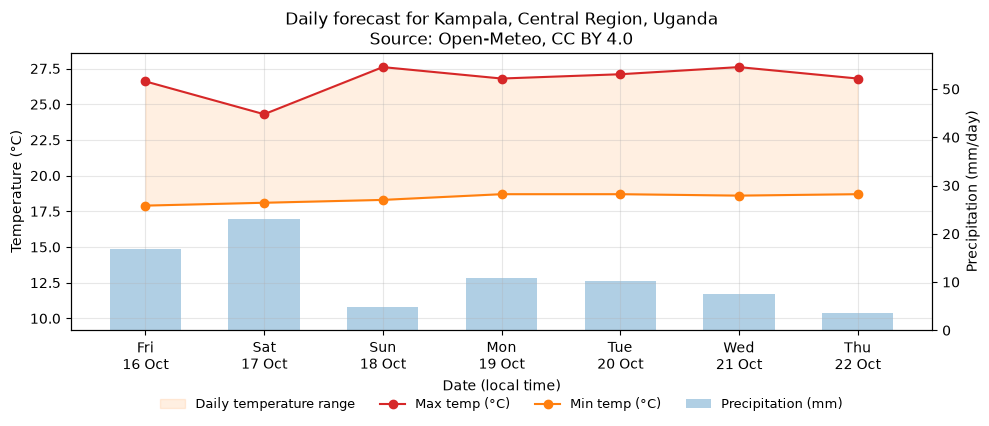

In [14]:
fig = plot_forecast(forecast, location)
fig.savefig(FIGURES / "p1_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

## Part C: Robustness and a second source

### C.1 One wrapper for every request

Every request goes through `fetch_json` (`src/weather/http.py`), which:

* sets a **timeout** on every call (it rejects a timeout of zero or less);
* calls **`raise_for_status()`**;
* **retries** connection errors, timeouts, HTTP 429 and 5xx, with **exponential backoff** (0.5 s, 1 s, 2 s, … up to `backoff_cap`) and a **retry cap** (`max_retries`);
* does **not** retry other 4xx responses, because those mean the request is wrong;
* raises the custom **`WeatherAPIError`** on final failure, carrying the URL, status, attempt count and the server's own reason.

The exception hierarchy is `WeatherError` → `WeatherAPIError`, `LocationNotFoundError` and `ConfigurationError`.

In [15]:
print(inspect.getsource(fetch_json)[:1500], "...")

def fetch_json(url: str, params: Mapping[str, Any] | None = None, *,
               headers: Mapping[str, str] | None = None,
               timeout: float = DEFAULT_TIMEOUT,
               policy: RetryPolicy = RetryPolicy(),
               session: requests.Session | None = None,
               sleep: Callable[[float], None] = time.sleep,
               log: Callable[[str], None] | None = None) -> tuple[Any, ResponseInfo]:
    """GET ``url`` and return ``(decoded_json, ResponseInfo)``, retrying transient failures.

    Args:
        url: Endpoint without query string.
        params: Query parameters, encoded by ``requests``.
        headers: Extra headers, e.g. ``User-Agent`` for MET Norway.
        timeout: Seconds for connect and read. Must be positive.
        policy: Retry policy (attempts = ``policy.max_retries + 1``).
        session: A ``requests.Session``, or any object with a compatible ``get``.
            Tests pass a fake here to simulate an outage without a network.
   

### C.2 Deliberately broken inputs

**1. An invalid city.**

In [16]:
try:
    geocode("Atlantis-Under-Lake-Victoria")
except LocationNotFoundError as exc:
    print(type(exc).__name__, "->", exc)
except WeatherAPIError as exc:
    print("(offline)", exc)

LocationNotFoundError -> No location found for 'Atlantis-Under-Lake-Victoria'. Check the spelling or try a larger nearby town.


**2. An invalid latitude.** Local validation catches it before any traffic is sent. With validation switched off, the server answers HTTP 400 with a reason. That reason is surfaced, and the request is not retried.

In [17]:
try:
    get_forecast(95, 32.58, 3)
except ValueError as exc:
    print("Local validation  ->", exc)

log = []
try:
    get_forecast(95, 32.58, 3, validate=False)
except WeatherAPIError as exc:
    print(f"Server rejection  -> status={exc.status}, attempts={exc.attempts}, reason={exc.reason!r}")

Local validation  -> Latitude must be between -90 and 90, got 95
Server rejection  -> status=400, attempts=1, reason='Latitude must be in range of -90 to 90°. Given: 95.0.'


**3. No network (simulated).** A fake session raises `ConnectionError` on every call, standing in for a lost connection. The log shows the backoff doubling until the retry cap, then the custom exception. A short `backoff_base` keeps the demo fast; the defaults are 0.5 s doubling to an 8 s cap.

In [18]:
class NoNetworkSession:
    """Behaves like requests.Session, but the network is always down."""
    calls = 0
    def get(self, url, **kwargs):
        NoNetworkSession.calls += 1
        raise requests.ConnectionError("[Errno 8] nodename nor servname provided, or not known (simulated)")

t0 = time.perf_counter()
try:
    fetch_json(GEOCODING_URL, {"name": "Gulu"}, session=NoNetworkSession(),
               policy=RetryPolicy(max_retries=3, backoff_base=0.1), log=print)
except WeatherAPIError as exc:
    print(f"\nWeatherAPIError after {exc.attempts} attempts in {time.perf_counter()-t0:.2f} s: {exc}")

attempt 1/4 failed (ConnectionError: [Errno 8] nodename nor servname provided, or not known (simulated)); retrying in 0.10 s
attempt 2/4 failed (ConnectionError: [Errno 8] nodename nor servname provided, or not known (simulated)); retrying in 0.20 s
attempt 3/4 failed (ConnectionError: [Errno 8] nodename nor servname provided, or not known (simulated)); retrying in 0.40 s
attempt 4/4 failed (ConnectionError: [Errno 8] nodename nor servname provided, or not known (simulated)); giving up

WeatherAPIError after 4 attempts in 0.70 s: Gave up on https://geocoding-api.open-meteo.com/v1/search after 4 attempts: ConnectionError: [Errno 8] nodename nor servname provided, or not known (simulated)


**4. A tiny timeout.** 1 ms is too short for a TLS handshake to Europe, so each attempt raises `requests.Timeout` (or `ConnectionError` if DNS fails first), and the wrapper retries before giving up.

In [19]:
try:
    fetch_json(GEOCODING_URL, {"name": "Gulu"}, timeout=0.001,
               policy=RetryPolicy(max_retries=2, backoff_base=0.2), log=print)
except WeatherAPIError as exc:
    print(f"\nWeatherAPIError: {exc}")

attempt 1/3 failed (ConnectTimeout: HTTPSConnectionPool(host='geocoding-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/search?name=Gulu (Caused by ConnectTimeoutError(<HTTPSConnection(host='geocoding-api.open-meteo.com', port=443) at 0x22e17d43610>, 'Connection to geocoding-api.open-meteo.com timed out. (connect timeout=0.001)'))); retrying in 0.20 s
attempt 2/3 failed (ConnectTimeout: HTTPSConnectionPool(host='geocoding-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/search?name=Gulu (Caused by ConnectTimeoutError(<HTTPSConnection(host='geocoding-api.open-meteo.com', port=443) at 0x22e187dc910>, 'Connection to geocoding-api.open-meteo.com timed out. (connect timeout=0.001)'))); retrying in 0.40 s
attempt 3/3 failed (ConnectTimeout: HTTPSConnectionPool(host='geocoding-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/search?name=Gulu (Caused by ConnectTimeoutError(<HTTPSConnection(host='geocoding-api.open-meteo.com', port=443) at 

### C.3 Second source: MET Norway Locationforecast 2.0

MET Norway returns a time series in **UTC** at mixed resolution: hourly for about 2.5 days, then 6-hourly. To compare it with Open-Meteo's daily values, `metno_to_daily`:

1. converts timestamps to the location's time zone, so days are local days (Kampala is UTC+3);
2. reads precipitation from `next_1_hours` where entries are hourly and from `next_6_hours` where they are 6-hourly. Summing both would count the same rain several times; `tests/test_weather.py` checks this;
3. takes the daily max and min of the instantaneous temperature, and the maximum wind;
4. records `Hours covered`, so that partial first and last days are left out of the comparison.

MET Norway's terms require a User-Agent with real contact details. `build_user_agent` refuses the placeholder email. In that case the saved response in `data/samples/metno_kampala.json` is used, and the output says so.

In [20]:
try:
    user_agent = build_user_agent(APP_NAME, CONTACT_EMAIL)
    met_raw = get_metno_forecast(location.latitude, location.longitude, user_agent)
    met_source = "MET Norway (live)"
except ConfigurationError as exc:
    print("ConfigurationError:", exc)
    print("-> using the saved MET Norway sample for Kampala instead.\n")
    met_raw, met_source = load_sample("metno_kampala"), "MET Norway (saved sample)"
except WeatherAPIError as exc:
    print("MET Norway request failed:", exc, "\n-> using the saved sample.\n")
    met_raw, met_source = load_sample("metno_kampala"), "MET Norway (saved sample)"

met_daily = metno_to_daily(met_raw, location.timezone if location.timezone != "auto" else "UTC")
print(f"{met_source}: updated {met_raw['properties']['meta']['updated_at']}, {len(met_raw['properties']['timeseries'])} time steps")
met_daily.round(1)

ConfigurationError: Contact email is still the placeholder. MET Norway requires real contact details; set WEATHER_CONTACT_EMAIL to your university email.
-> using the saved MET Norway sample for Kampala instead.

MET Norway (saved sample): updated 2026-10-13T23:20:44Z, 89 time steps


,Max temp (°C),Min temp (°C),Precipitation (mm),Max wind (m/s),Hours covered
Date,,,,,
2026-10-14,27.3,18.8,1.5,2.8,21.0
2026-10-15,26.8,19.3,5.6,4.9,24.0
2026-10-16,25.3,18.8,10.2,5.5,27.0
2026-10-17,23.3,20.0,16.1,2.5,24.0
2026-10-18,23.5,19.1,6.4,2.3,24.0
2026-10-19,25.1,19.3,2.3,1.6,24.0
2026-10-20,25.8,19.3,11.3,2.0,24.0
2026-10-21,26.3,19.6,10.4,2.0,24.0
2026-10-22,25.4,19.2,2.4,2.9,24.0


Comparing like with like: when MET Norway comes from the saved sample (fetched on 14 Oct 2026 for Kampala), it is compared with the Open-Meteo response saved at the same moment for the same place. Otherwise the two forecasts would cover different days, or different places.

In [21]:
primary = forecast
if "sample" in met_source:
    primary = forecast_to_dataframe(load_sample("forecast_kampala"))
    print("Comparing against the Open-Meteo sample saved at the same time as the MET Norway sample.")
comparison = compare_sources(primary, met_daily)
comparison.round(1)

Comparing against the Open-Meteo sample saved at the same time as the MET Norway sample.


Open-Meteo                                                    MET Norway                                                  \
           Max temp (°C) Min temp (°C) Precipitation (mm) Max wind (m/s) Max temp (°C) Min temp (°C) Precipitation (mm) Max wind (m/s)   
Date                                                                                                                                     
2026-10-15          27.4          19.2                5.1            4.3          26.8          19.3                5.6            4.9   
2026-10-16          25.6          18.9               10.0            3.4          25.3          18.8               10.2            5.5   
2026-10-17          23.8          18.7               16.8            2.5          23.3          20.0               16.1            2.5   
2026-10-18          26.2          18.8                5.7            2.0          23.5          19.1                6.4            2.3   
2026-10-19          25.4          18.4                3.3            2.0          25.1          19.3                2.3            1.6   
2026-10-20          26.1          18.2               13.2            2.2          25.8          19.3               11.3            2.0   

              Difference                                                  
           Max temp (°C) Min temp (°C) Precipitation (mm) Max wind (m/s)  
Date                                                                      
2026-10-15          -0.6           0.1                0.5            0.6  
2026-10-16          -0.3          -0.1                0.2            2.1  
2026-10-17          -0.5           1.3               -0.7           -0.0  
2026-10-18          -2.7           0.3                0.7            0.3  
2026-10-19          -0.3           0.9               -1.0           -0.4  
2026-10-20          -0.3           1.1               -1.9           -0.2

In [22]:
diff = comparison["Difference"]
print("Mean absolute difference, MET Norway vs Open-Meteo, over", len(diff), "full days:")
print(diff.abs().mean().round(2).to_string())

Mean absolute difference, MET Norway vs Open-Meteo, over 6 full days:
Max temp (°C)         0.78
Min temp (°C)         0.63
Precipitation (mm)    0.83
Max wind (m/s)        0.60


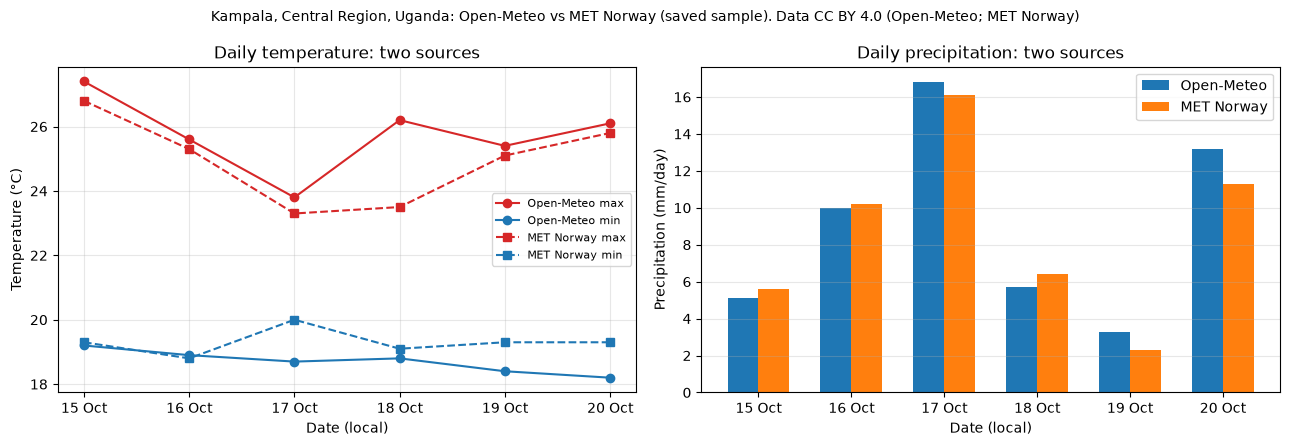

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
days = comparison.index
ax = axes[0]
for src, style in (("Open-Meteo", "-o"), ("MET Norway", "--s")):
    ax.plot(days, comparison[(src, "Max temp (°C)")], style, color="tab:red", label=f"{src} max")
    ax.plot(days, comparison[(src, "Min temp (°C)")], style, color="tab:blue", label=f"{src} min")
ax.set_title("Daily temperature: two sources"); ax.set_ylabel("Temperature (°C)"); ax.set_xlabel("Date (local)")
ax.legend(fontsize=8); ax.grid(alpha=.3)
ax = axes[1]
w = pd.Timedelta(hours=8)
ax.bar(days - w/2, comparison[("Open-Meteo", "Precipitation (mm)")], width=w, label="Open-Meteo")
ax.bar(days + w/2, comparison[("MET Norway", "Precipitation (mm)")], width=w, label="MET Norway")
ax.set_title("Daily precipitation: two sources"); ax.set_ylabel("Precipitation (mm/day)"); ax.set_xlabel("Date (local)")
ax.legend(); ax.grid(alpha=.3, axis="y")
for a in axes:
    a.set_xticks(days); a.set_xticklabels([d.strftime("%d %b") for d in days])
fig.suptitle(f"{location.label}: Open-Meteo vs {met_source}. Data CC BY 4.0 (Open-Meteo; MET Norway)", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES / "p1_source_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

The two services broadly agree on temperature (within about 1 °C on most days). They differ more on rain, which is normal: convective showers over Lake Victoria are hard to place in time and space, and each service runs its own models and grid. For a farmer or a trip planner, the useful signal is where both sources agree, for example on the wettest day. A single precise number from one source is less useful.

### C.4 Offline checks on the parsing functions

These assertions run against saved JSON, so they pass without a network. The complete set (22 tests, including the retry logic with a fake session) is in `tests/test_weather.py`, and the cell after these assertions runs it.

In [24]:
kampala = parse_geocoding(load_sample("geocode_kampala"))
assert kampala[0].country == "Uganda" and kampala[0].timezone == "Africa/Kampala"          # 1 best match first
assert parse_geocoding(load_sample("geocode_no_results")) == []                            # 2 absent 'results' key
assert len(parse_geocoding(load_sample("geocode_springfield"))) > 1                        # 3 ambiguous name
df = forecast_to_dataframe(load_sample("forecast_kampala"))
assert {"Max temp (°C)", "Min temp (°C)", "Precipitation (mm)", "Max wind (m/s)"} <= set(df.columns)  # 4 units in names
assert (df["Max temp (°C)"] >= df["Min temp (°C)"]).all() and "Unknown" not in "".join(df["Conditions"])  # 5 sane + decoded
md_daily = metno_to_daily(load_sample("metno_kampala"), "Africa/Kampala")
assert md_daily.index[0] == pd.Timestamp("2026-10-14") and md_daily["Hours covered"].iloc[0] < 24      # 6 local, partial day
print("6 offline assertions passed")

6 offline assertions passed


In [25]:
import subprocess, os, sys

my_env = os.environ.copy()
my_env["HYPOTHESIS_NO_NATIVE"] = "1"
my_env["HYPOTHESIS_NO_NAT_EXTENSION"] = "1"

result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/test_weather.py"],
    env=my_env,
    capture_output=True,
    text=True
)
print(result.stdout[-800:] or result.stderr[-800:])

......................                                                   [100%]
22 passed in 2.27s



## Part D: Report

### D.1 Data flow from user input to displayed forecast

```
 ┌──────────────────┐   name    ┌──────────────────────────┐  JSON  ┌────────────────────┐
 │ Config cell      │──────────▶│ geocode(name)            │───────▶│ parse_geocoding()  │
 │ LOCATION, EMAIL  │           │ Open-Meteo Geocoding API │        │ -> [Location, ...] │
 └──────────────────┘           └──────────────────────────┘        └─────────┬──────────┘
                                                                              │ choose_location()
                                                                              ▼ (prompt only if ambiguous)
 ┌────────────────────────────── fetch_json(): timeout · raise_for_status · retry + backoff ──┐
 │  get_forecast(lat, lon, days, timezone)            get_metno_forecast(lat, lon, UA)        │
 │  Open-Meteo Forecast API (daily, local tz)         MET Norway Locationforecast (UTC series)│
 └──────────────┬─────────────────────────────────────────────────────┬──────────────────────┘
                ▼ JSON                                                ▼ JSON
     forecast_to_dataframe()                              metno_to_daily(tz)
     units in column names, WMO code → text               UTC → local days, no double counting
                │                                                     │
                └──────────────┬──────────────────────────────────────┘
                               ▼
        summarise() · format_table() · plot_forecast() · compare_sources()
                               ▼
                   text summary, table, charts (figures/)
   Any failure ──▶ WeatherError subclass with a clear message (never a bare KeyError)
```

The user supplies a name, and everything after that is a chain of small functions. Each function takes plain data and returns plain data, which is what makes them testable offline. `geocode` turns the name into candidate `Location` objects. `choose_location` resolves ambiguity. `get_forecast` requests the daily variables with `timezone` set, so that a "day" means a local calendar day in Kampala, not a UTC day that starts at 03:00 local time. The parser then renames the fields into unit-bearing column names and decodes the WMO weather codes. The second source goes through the same HTTP wrapper but needs an extra transformation step, because MET Norway returns a raw time series and not daily aggregates.

### D.2 Licensing and usage terms, and what they mean for a real product

**Open-Meteo** (geocoding and forecast). The data is licensed **CC BY 4.0**: it may be used and redistributed, including commercially, provided Open-Meteo is credited. The geocoder's place names also come from GeoNames under CC BY 4.0. The *free API endpoint*, however, is for **non-commercial use only**, with fair-use limits of roughly 10,000 calls a day, 5,000 an hour and 600 a minute, and no API key. A commercial product, such as a paid farm-advisory app, would need a paid API subscription (a separate endpoint with an API key and a contractual service level), or it could self-host the open-source Open-Meteo server (AGPL-3.0, which brings its own source-sharing obligations if modified and offered as a network service). For a real product, the attribution therefore has to appear in the user interface, and the commercial question has to be settled before launch, not after.

**MET Norway** (Locationforecast 2.0). The data is free under the **Norwegian Licence for Open Government Data (NLOD) 2.0 and CC BY 4.0**, and commercial use is allowed with attribution. The *service* has strict terms. Every request must carry a User-Agent that identifies the application and a contact, and generic agents are blocked with HTTP 403. Clients must cache responses and honour the `Expires` and `Last-Modified` headers, and must not poll more often than the data changes. Coordinates should be truncated to at most four decimals so that caches work. Total traffic above about 20 requests per second per application needs prior agreement. There is no service-level guarantee, and MET can throttle (429) or block clients that misbehave. A product serving many users must therefore not call MET from each user's device. It should put a caching proxy in between that rounds coordinates, so that thousands of users in Kampala share one cached response.

Both providers also ask to be cited where the data is shown. This notebook does so in every chart title and in the text summary, which is the pattern a product should follow on every screen that shows a forecast.

**Implication.** Both sources are "open", but *open data* is not the same as *an unlimited free service*. A real product needs attribution in the UI, a cache, a request budget and, for Open-Meteo, a commercial plan.

### D.3 Reliability issues met, and how the code handles them

* **Absent keys.** A geocoding search with no matches returns `{"generationtime_ms": ...}` with no `results` key. `parse_geocoding` uses `payload.get("results") or []`, and `geocode` raises `LocationNotFoundError`, a message a user can act on.
* **Ambiguity.** "Springfield" matches dozens of places, and even "Kampala" matches a village in Côte d'Ivoire. Candidates are labelled with region and country and can be chosen in advance from the config cell, or interactively with re-prompting on invalid answers.
* **Bad input.** An impossible latitude is caught locally before any traffic. If it reaches the server, the HTTP 400 body (`{"error": true, "reason": ...}`) is carried inside `WeatherAPIError.reason`, and the request is not retried, because retrying a client error only adds load.
* **Transient failures.** Connection errors, timeouts, 429 and 5xx responses are retried with capped exponential backoff (0.5 s, 1 s, 2 s, …). Backoff gives an overloaded server time to recover, and the cap keeps a user from waiting forever. On mobile data in Uganda, short outages are common, so this matters in practice. The simulated outage and the 1 ms timeout above show the full path to the custom exception.
* **Time zones and resolution.** MET Norway reports UTC and switches from hourly to 6-hourly steps. A naive daily grouping would shift each day by three hours and could triple-count rain. The parser converts time zones, picks the right precipitation window and reports partial days, which the comparison then excludes.
* **Units.** Open-Meteo's default wind unit is km/h, while MET Norway reports m/s. The code requests m/s from Open-Meteo, and every column name carries its unit.
* **Keeping traffic low.** The notebook makes about a dozen requests per full run. Retries are capped, client errors are never retried, and MET Norway is called at most once. In a product the next step would be a response cache keyed on rounded coordinates that honours MET's `Expires` header, so that repeated runs within the validity period send no request at all.
* **Offline execution.** Every live call has a fallback to the saved sample, labelled as such, so the notebook still runs top to bottom without a network.

### D.4 Privacy implications of sending location queries to third parties

A weather lookup looks harmless, but it reveals where the user is, or cares about, at a given time, and the provider also receives the user's IP address. Repeated over days, the queries can expose a home, a workplace or a travel pattern. Under Uganda's **Data Protection and Privacy Act, 2019**, location linked to an identifiable person is personal data. For MET Norway, which sits in the EEA, the **GDPR** also applies on the receiving side. A product built on this code should:

1. **Minimise precision.** Weather does not vary meaningfully over 100 m, so coordinates can be rounded to two or three decimals (about 1 km or 100 m) before sending. This code already truncates to four decimals.
2. **Proxy and cache server-side**, so that the third party sees the product's server, not each user's IP address. Caching also cuts the number of queries that reveal anything.
3. **Avoid identifiers.** The User-Agent identifies the *developer*, as MET requires, never the end user. Nothing else identifying should be sent.
4. **Tell users**, in the privacy notice, which third parties receive their location and why, and keep logs of location queries only as long as necessary.
5. **Keep secrets out of shared code.** The contact email is read from an environment variable, and the shared notebook contains only a placeholder, as this assignment requires.

Both providers publish privacy policies, but once a query leaves the device the user depends on those policies. Sending less is the only control the product fully owns.

In [26]:
import re
cells = json.loads(Path("project1_weather.ipynb").read_text(encoding="utf-8"))["cells"]
report_md = "\n".join("".join(c["source"]) for c in cells
                      if c["cell_type"] == "markdown" and "".join(c["source"]).startswith("## Part D"))
words = len(re.findall(r"[A-Za-z0-9][A-Za-z0-9'’.,%/-]*", re.sub(r"```.*?```", "", report_md, flags=re.S)))
print(f"Part D length: {words} words (target 1,000-1,500; the diagram is excluded)")

Part D length: 1127 words (target 1,000-1,500; the diagram is excluded)


*Data sources: Open-Meteo.com (CC BY 4.0); MET Norway (NLOD 2.0 / CC BY 4.0); GeoNames (CC BY 4.0).*